### DECISION TREE - REGRESSION

import libraries and load data.


In [11]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree


df = pd.read_csv("teen_phone_addiction_dataset.csv")

y = df["Addiction_Level"]
X = df.drop(columns=["Addiction_Level", "ID", "Name", "Location"])

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (3000, 25)


,ID,Name,Age,Gender,Location,School_Grade,Daily_Usage_Hours,Sleep_Hours,Academic_Performance,Social_Interactions,...,Screen_Time_Before_Bed,Phone_Checks_Per_Day,Apps_Used_Daily,Time_on_Social_Media,Time_on_Gaming,Time_on_Education,Phone_Usage_Purpose,Family_Communication,Weekend_Usage_Hours,Addiction_Level
0,1,Shannon Francis,13,Female,Hansonfort,9th,4.0,6.1,78,5,...,1.4,86,19,3.6,1.7,1.2,Browsing,4,8.7,10.0
1,2,Scott Rodriguez,17,Female,Theodorefort,7th,5.5,6.5,70,5,...,0.9,96,9,1.1,4.0,1.8,Browsing,2,5.3,10.0
2,3,Adrian Knox,13,Other,Lindseystad,11th,5.8,5.5,93,8,...,0.5,137,8,0.3,1.5,0.4,Education,6,5.7,9.2
3,4,Brittany Hamilton,18,Female,West Anthony,12th,3.1,3.9,78,8,...,1.4,128,7,3.1,1.6,0.8,Social Media,8,3.0,9.8
4,5,Steven Smith,14,Other,Port Lindsaystad,9th,2.5,6.7,56,4,...,1.0,96,20,2.6,0.9,1.1,Gaming,10,3.7,8.6


train test split and conversion of textual categories to numerical

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Fill missing values using training-set statistics
for column in X_train.columns:
    if pd.api.types.is_numeric_dtype(X_train[column]):
        fill_value = X_train[column].median()
    else:
        fill_value = X_train[column].mode().iloc[0]

    X_train[column] = X_train[column].fillna(fill_value)
    X_test[column] = X_test[column].fillna(fill_value)

    
X_train = pd.get_dummies(X_train, dtype=int)
X_test = pd.get_dummies(X_test, dtype=int)

# Make sure the test set has the same columns as the training set
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

The model needs numeric inputs, so get_dummies() converts categorical columns into indicator columns.

Train the decision tree regressor

In [13]:
from sklearn.tree import DecisionTreeRegressor

model = DecisionTreeRegressor(
    criterion="squared_error",
    max_depth=4,
    min_samples_leaf=5,
    random_state=42
)

model.fit(X_train, y_train);

A regression tree splits the data into groups and predicts a numerical value in each leaf, typically the average target score in that leaf. max_depth and min_samples_leaf limit tree growth to help reduce overfitting.

Predict and evaluate

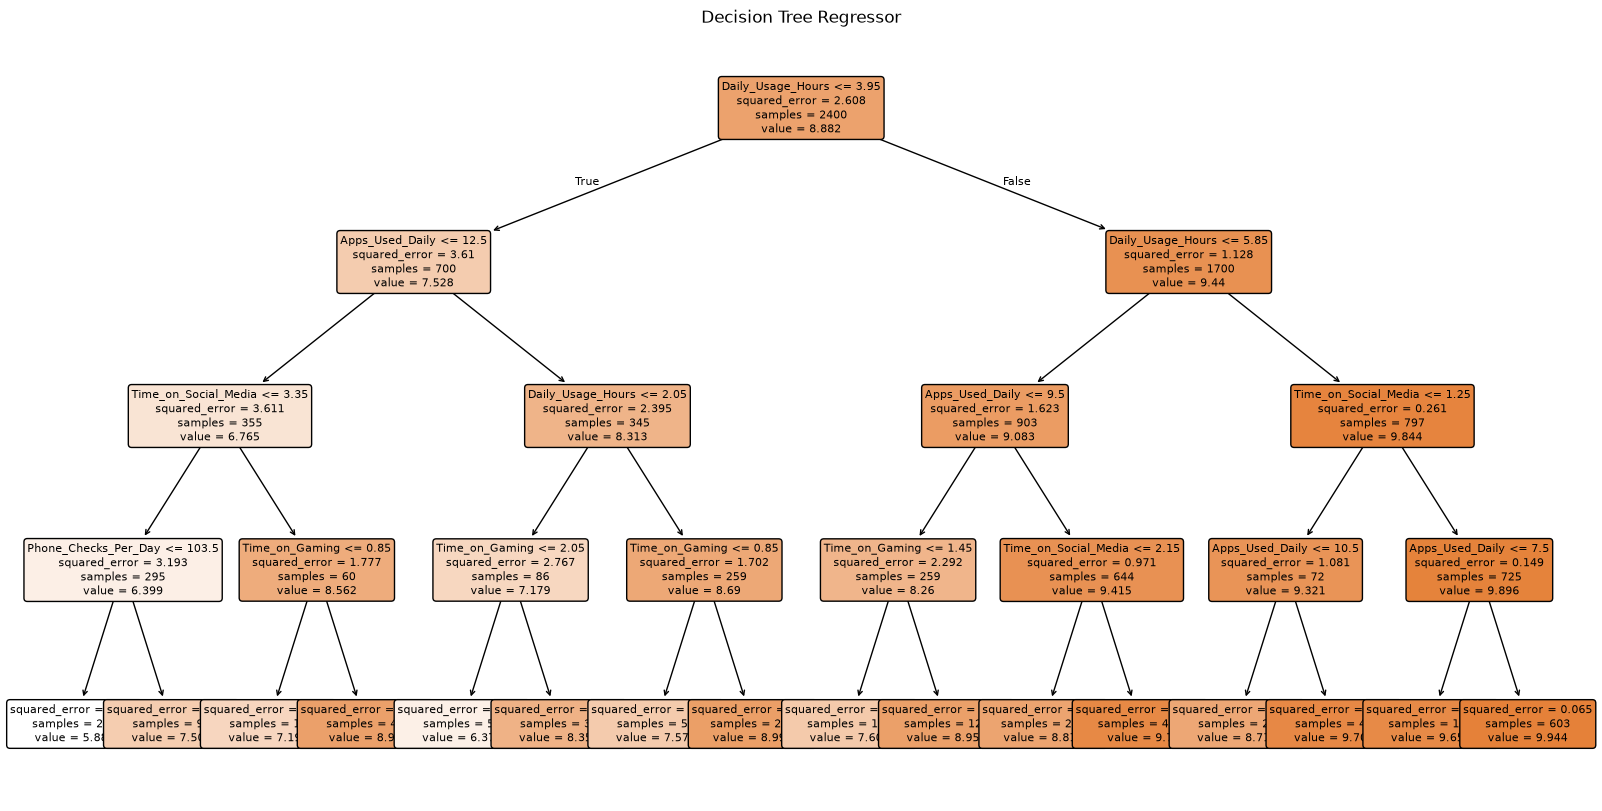

In [14]:
plt.figure(figsize=(20, 10))

plot_tree(
    model,
    feature_names=X_train.columns,
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree Regressor")
plt.show()

In [15]:
predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
rmse = mean_squared_error(y_test, predictions) ** 0.5
r2 = r2_score(y_test, predictions)

print(f"MAE:  {mae:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R²:   {r2:.3f}")

MAE:  0.755
RMSE: 1.104
R²:   0.516


Compare actual and predicted scores

In [16]:
comparison = pd.DataFrame({
    "Actual Addiction_Level": y_test,
    "Predicted Addiction_Level": predictions
})

display(comparison.head(10))

,Actual Addiction_Level,Predicted Addiction_Level
1801,10.0,8.812560
1190,10.0,9.699771
1817,10.0,9.944444
251,9.0,8.990686
2505,10.0,9.699771
1117,8.7,7.572727
1411,4.6,6.372549
2113,10.0,9.699771
408,10.0,9.655738
2579,10.0,9.944444


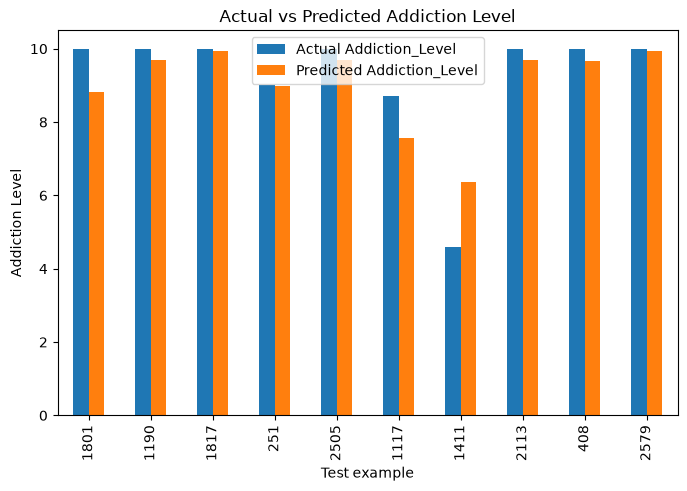

In [17]:
import matplotlib.pyplot as plt

comparison.head(10).plot(kind="bar", figsize=(8, 5))
plt.title("Actual vs Predicted Addiction Level")
plt.xlabel("Test example")
plt.ylabel("Addiction Level")
plt.show()